# Notebook 6: Autoencoder-Based Dimensionality Reduction (Optional)

This notebook explores autoencoder neural networks as an alternative to PCA for dimensionality reduction of yield curve data. While PCA captures linear relationships, autoencoders can potentially capture nonlinear patterns in interest rate movements.

**Prerequisites**:
- Notebooks 01 (Data Loading) and 03 (PCA Analysis) completed
- PyTorch installed: `pip install torch` or `pip install hjm-vasicek-modeling[autoencoder]`

**Learning Objectives**:
1. Understand autoencoder architecture for yield curve data
2. Train and evaluate an autoencoder model
3. Compare reconstruction quality: PCA vs. Autoencoder
4. Visualize latent space representations

## 1. Setup and Imports

In [3]:
# Standard imports
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Check if PyTorch is available
try:
    import torch
    print(f"PyTorch version: {torch.__version__}")
    print(f"CUDA available: {torch.cuda.is_available()}")
except ImportError:
    print("PyTorch not installed. Install with: pip install torch")
    print("Or: pip install hjm-vasicek-modeling[autoencoder]")
    raise

PyTorch version: 2.9.1+cu128
CUDA available: False


In [4]:
# Project imports
from src.data.loader import load_interest_rate_data
from src.analysis.pca import compute_pca, compute_yield_curve_changes, _get_changes_matrix, reconstruct_curve
from src.analysis.autoencoder import (
    YieldCurveAutoencoder,
    train_autoencoder,
    compare_dimensionality_methods,
    get_latent_encodings,
)
from src.visualization.pca_plots import (
    plot_training_loss,
    plot_latent_space,
    plot_reconstruction_comparison,
    plot_explained_variance,
    plot_component_loadings,
)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 100

## 2. Load Interest Rate Data

In [5]:
# Load sample treasury rates
data_path = project_root / "data" / "sample_treasury_rates.csv"
dataset = load_interest_rate_data(str(data_path))

print(f"Loaded {dataset.n_observations} observations")
print(f"Date range: {dataset.observation_dates[0]} to {dataset.observation_dates[-1]}")
print(f"Maturities: {dataset.maturities}")
print(f"Rate matrix shape: {dataset.rates.shape}")

2026-01-20 22:50:25 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from /home/haydar/personal/act/data/sample_treasury_rates.csv
2026-01-20 22:50:25 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from sample_treasury_rates
Loaded 252 observations
Date range: 2024-01-02 to 2024-12-18
Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]
Rate matrix shape: (252, 7)


In [6]:
# Compute yield curve changes (input for dimensionality reduction)
changes = compute_yield_curve_changes(dataset)
changes_matrix = _get_changes_matrix(changes)

print(f"Number of yield curve changes: {len(changes)}")
print(f"Changes matrix shape: {changes_matrix.shape}")
print(f"Change statistics:")
print(f"  Mean: {changes_matrix.mean():.6f}")
print(f"  Std:  {changes_matrix.std():.6f}")
print(f"  Min:  {changes_matrix.min():.6f}")
print(f"  Max:  {changes_matrix.max():.6f}")

2026-01-20 22:50:25 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:50:25 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
Number of yield curve changes: 251
Changes matrix shape: (251, 7)
Change statistics:
  Mean: 0.000012
  Std:  0.000492
  Min:  -0.001662
  Max:  0.001681


## 3. Autoencoder Architecture

The autoencoder architecture used in this module:

```
Encoder: N → 64 → 32 → K (latent)
Decoder: K → 32 → 64 → N
```

Where:
- N = number of maturities (input dimension)
- K = latent dimension (typically 3 to match PCA's top 3 components)
- ReLU activation for hidden layers, linear for output

In [7]:
# Create autoencoder model
input_dim = len(dataset.maturities)
latent_dim = 3  # Match typical PCA components

model = YieldCurveAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
print(f"Autoencoder architecture:")
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

Autoencoder architecture:
YieldCurveAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=3, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)

Total parameters: 5,386


## 4. Train the Autoencoder

In [8]:
# Prepare training data
# Standardize the changes for better training
data_mean = changes_matrix.mean(axis=0)
data_std = changes_matrix.std(axis=0) + 1e-8
data_normalized = ((changes_matrix - data_mean) / data_std).astype(np.float32)

# Split into train/validation
n_samples = len(data_normalized)
n_train = int(0.8 * n_samples)
train_data = data_normalized[:n_train]
val_data = data_normalized[n_train:]

print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Training samples: 200
Validation samples: 51


In [9]:
# Train the autoencoder
# Reset model for fresh training
torch.manual_seed(42)
model = YieldCurveAutoencoder(input_dim=input_dim, latent_dim=latent_dim)

history = train_autoencoder(
    model=model,
    data=train_data,
    n_epochs=200,
    batch_size=32,
    learning_rate=0.001,
    validation_data=val_data,
)

print(f"\nFinal training loss: {history['train_loss'][-1]:.6f}")
print(f"Final validation loss: {history['val_loss'][-1]:.6f}")

2026-01-20 22:50:25 | INFO     | hjm_vasicek.analysis.autoencoder | Training autoencoder: 200 samples, 200 epochs, batch_size=32, lr=0.0010
2026-01-20 22:50:33 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 1/200 - train_loss: 0.951542, val_loss: 1.056408
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 10/200 - train_loss: 0.294317, val_loss: 0.324186
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 20/200 - train_loss: 0.184757, val_loss: 0.202641
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 30/200 - train_loss: 0.141369, val_loss: 0.157901
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 40/200 - train_loss: 0.111011, val_loss: 0.123056
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 50/200 - train_loss: 0.102095, val_loss: 0.122717
2026-01-20 22:50:34 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 60/200 - train_loss: 0.099096, val_loss: 0.

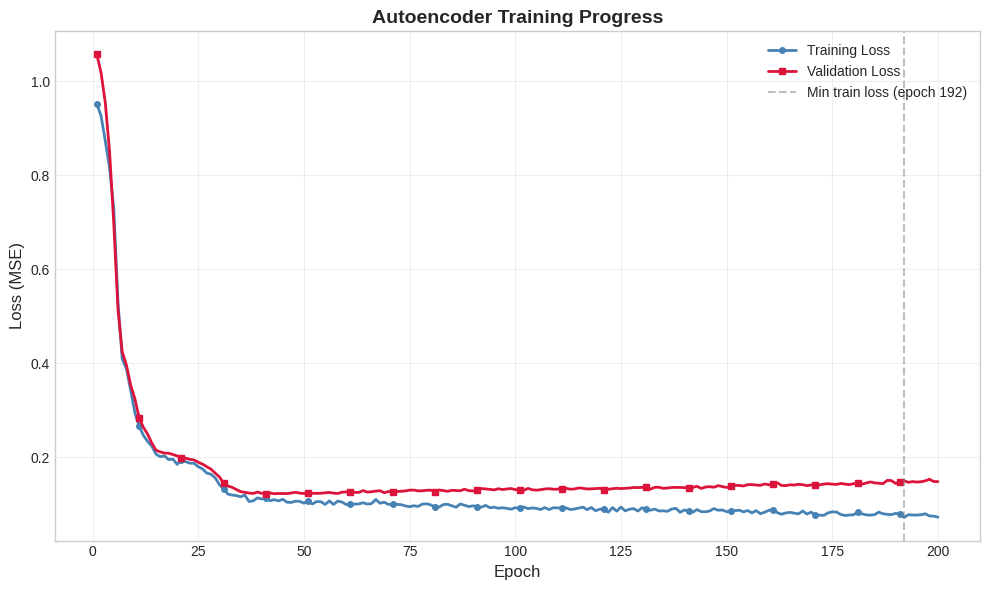

In [10]:
# Plot training loss curve
fig = plot_training_loss(history, title="Autoencoder Training Progress")
plt.show()

## 5. Compare with PCA

In [11]:
# Compute PCA for comparison
pca_result = compute_pca(dataset, n_components=latent_dim, use_changes=True)

print("PCA Results:")
for i, (var, interp) in enumerate(zip(pca_result.explained_variance_ratio, pca_result.interpretations)):
    print(f"  PC{i+1}: {var*100:.2f}% - {interp}")
print(f"\nTotal variance explained: {pca_result.cumulative_variance[-1]*100:.2f}%")

2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=3
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 3 components explain 88.82% of variance
PCA Results:
  PC1: 61.76% - PC1: Level (parallel shift) - uniform impact across maturities
  PC2: 18.78% - PC2: Slope (tilt) - steepening of yield curve
  PC3: 8.27% - PC3: Curvature (inverse butterfly) - belly vs wings movement

Total variance explained: 88.82%


In [12]:
# Use the comparison function for a comprehensive analysis
comparison = compare_dimensionality_methods(
    dataset=dataset,
    n_components=latent_dim,
    n_epochs=200,
    batch_size=32,
    learning_rate=0.001,
)

print("\n" + "="*60)
print("COMPARISON: PCA vs Autoencoder")
print("="*60)
print(f"Latent dimensions: {comparison.n_components}")
print(f"\nReconstruction MSE:")
print(f"  PCA:         {comparison.pca_reconstruction_error:.6e}")
print(f"  Autoencoder: {comparison.autoencoder_reconstruction_error:.6e}")
print(f"\nPCA Explained Variance: {comparison.pca_explained_variance*100:.2f}%")

# Determine winner
if comparison.autoencoder_reconstruction_error < comparison.pca_reconstruction_error:
    improvement = (1 - comparison.autoencoder_reconstruction_error / comparison.pca_reconstruction_error) * 100
    print(f"\n→ Autoencoder achieves {improvement:.1f}% lower reconstruction error")
else:
    print(f"\n→ PCA achieves equal or better reconstruction (expected for linear data)")

2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.autoencoder | Comparing PCA vs Autoencoder with 3 components/latent dimensions
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=3
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 3 components explain 88.82% of variance
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.autoencoder | PCA reconstruction MSE: 0.000000
2026-01-20 22:50:37 | INFO     | hjm_vasicek.analysis.autoencoder | Training autoencoder: 251 samples, 200 epochs, batch_size=32, lr=0.0010

## 6. Visualize Reconstruction Quality

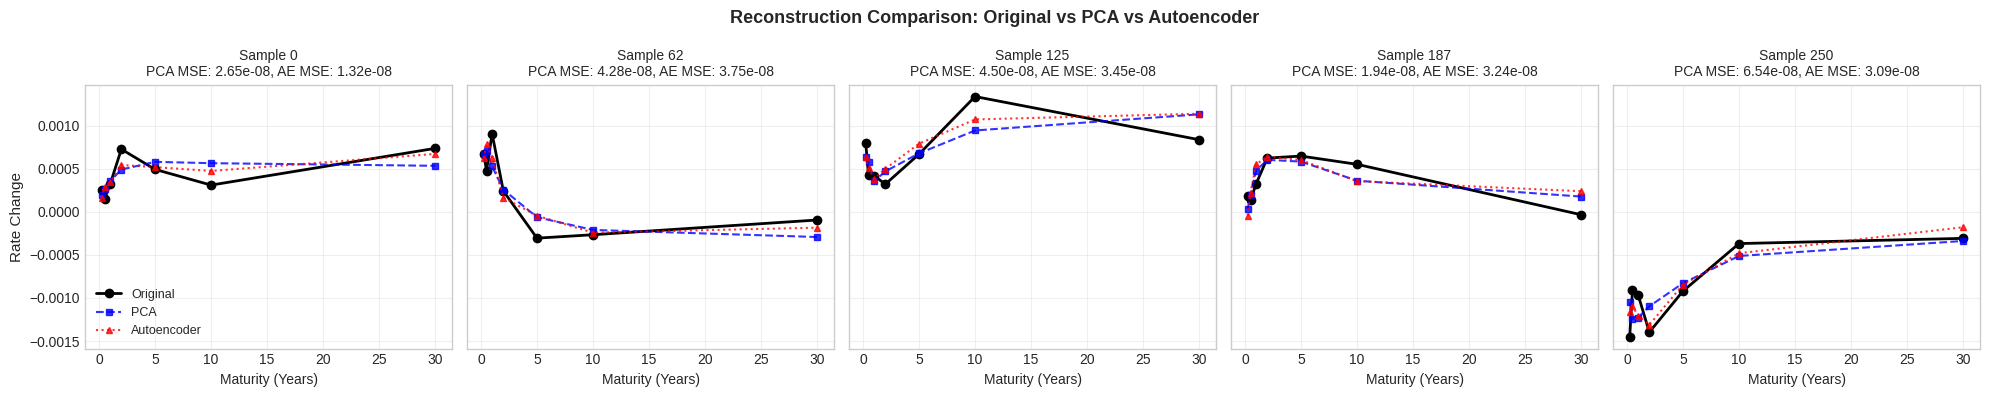

In [13]:
# Compute reconstructions for visualization
# PCA reconstruction
pca_reconstructed = np.zeros_like(changes_matrix)
for i, row in enumerate(changes_matrix - data_mean):
    pca_reconstructed[i] = reconstruct_curve(pca_result, latent_dim, row) + data_mean

# Autoencoder reconstruction
ae_reconstructed_norm = comparison.autoencoder.reconstruct_numpy(data_normalized)
ae_reconstructed = ae_reconstructed_norm * data_std + data_mean

# Plot comparison for selected samples
fig = plot_reconstruction_comparison(
    original=changes_matrix,
    pca_reconstructed=pca_reconstructed,
    autoencoder_reconstructed=ae_reconstructed,
    maturities=dataset.maturities,
    n_samples=5,
)
plt.show()

## 7. Latent Space Visualization

In [14]:
# Get latent encodings from the autoencoder
latent_encodings = get_latent_encodings(
    model=comparison.autoencoder,
    data=changes_matrix,
    normalize=True,
)

print(f"Latent encodings shape: {latent_encodings.shape}")
print(f"\nLatent dimension statistics:")
for i in range(latent_dim):
    print(f"  Dim {i+1}: mean={latent_encodings[:, i].mean():.3f}, std={latent_encodings[:, i].std():.3f}")

Latent encodings shape: (251, 3)

Latent dimension statistics:
  Dim 1: mean=1.763, std=1.775
  Dim 2: mean=0.680, std=2.303
  Dim 3: mean=0.213, std=1.817


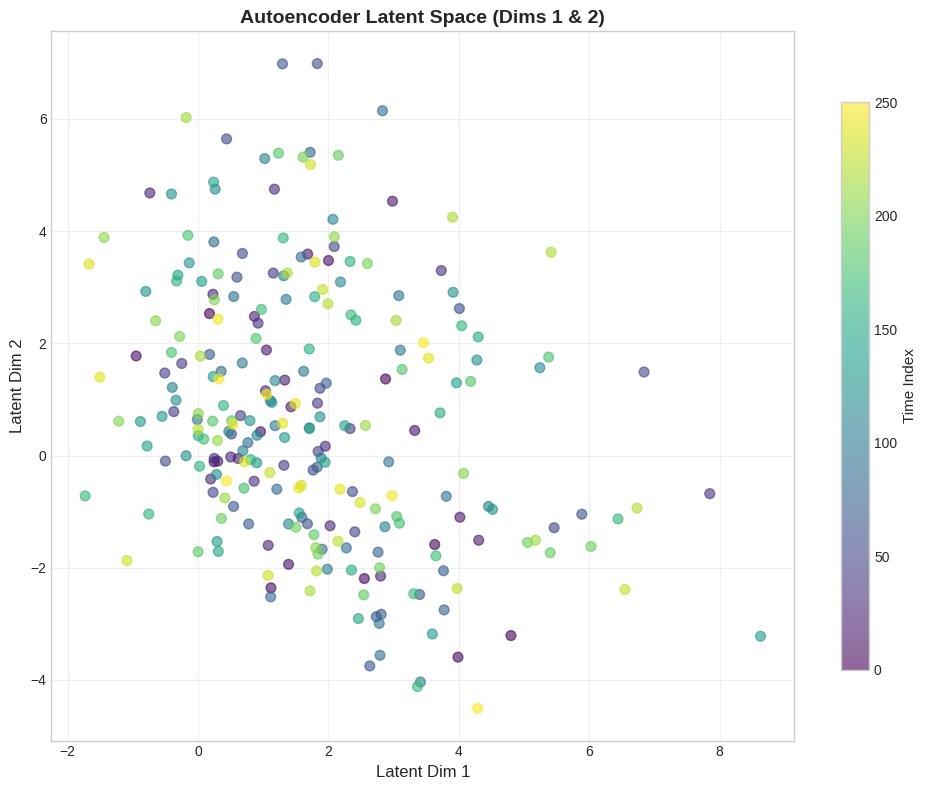

In [15]:
# 2D latent space visualization
# Color by time (observation index) to see temporal patterns
time_labels = np.arange(len(latent_encodings))

fig = plot_latent_space(
    encodings=latent_encodings,
    labels=time_labels,
    dims=(0, 1),
    title="Autoencoder Latent Space (Dims 1 & 2)",
    colorbar_label="Time Index",
)
plt.show()

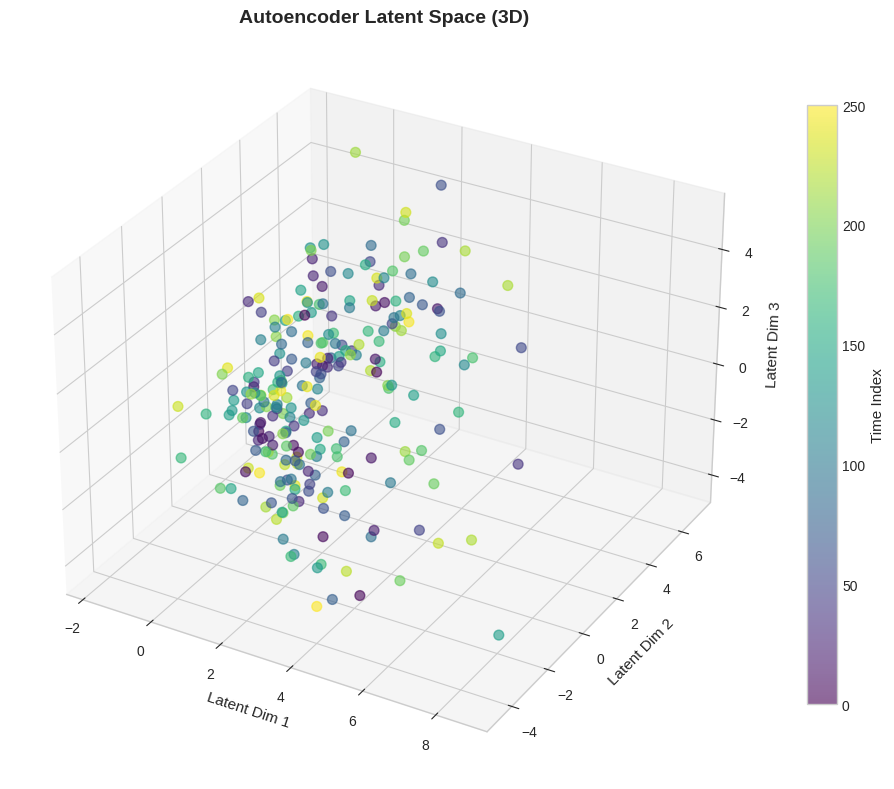

In [16]:
# 3D latent space visualization (all 3 dimensions)
if latent_dim >= 3:
    fig = plot_latent_space(
        encodings=latent_encodings,
        labels=time_labels,
        dims=(0, 1, 2),
        title="Autoencoder Latent Space (3D)",
        colorbar_label="Time Index",
    )
    plt.show()

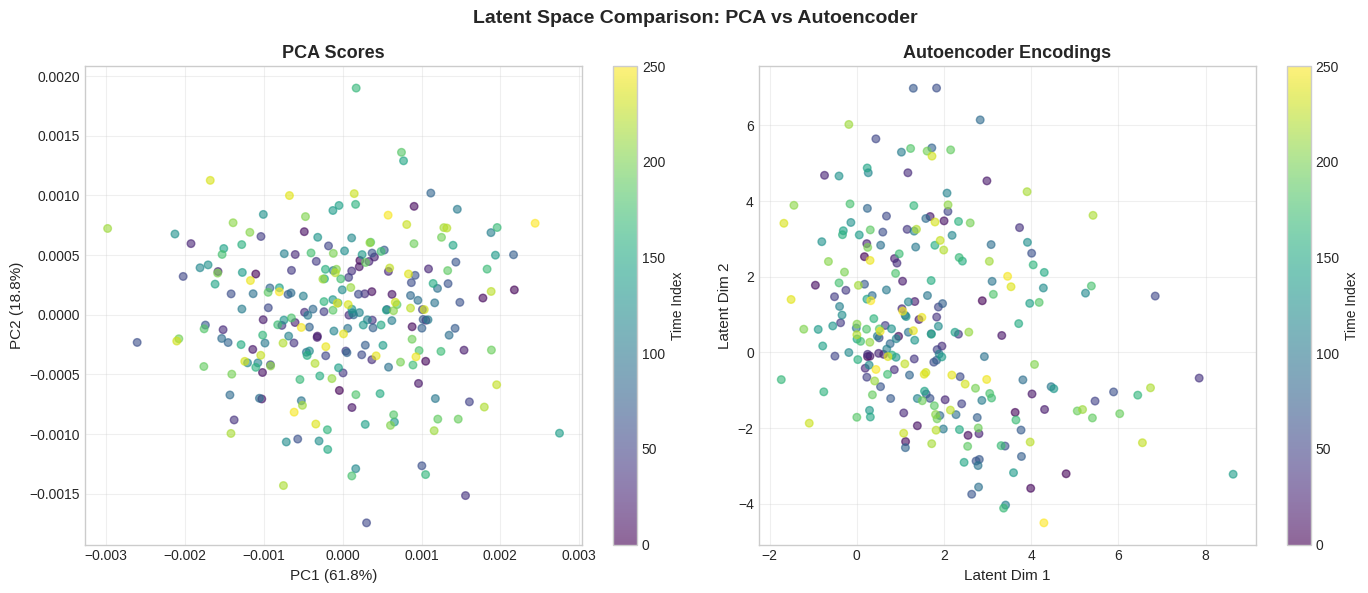

In [17]:
# Compare latent spaces: PCA scores vs Autoencoder encodings
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PCA scores
pca_scores = (changes_matrix - data_mean) @ pca_result.loadings

# Plot PCA scores
scatter1 = axes[0].scatter(
    pca_scores[:, 0],
    pca_scores[:, 1],
    c=time_labels,
    cmap='viridis',
    alpha=0.6,
    s=30,
)
axes[0].set_xlabel(f"PC1 ({pca_result.explained_variance_ratio[0]*100:.1f}%)", fontsize=11)
axes[0].set_ylabel(f"PC2 ({pca_result.explained_variance_ratio[1]*100:.1f}%)", fontsize=11)
axes[0].set_title("PCA Scores", fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label="Time Index")

# Plot Autoencoder encodings
scatter2 = axes[1].scatter(
    latent_encodings[:, 0],
    latent_encodings[:, 1],
    c=time_labels,
    cmap='viridis',
    alpha=0.6,
    s=30,
)
axes[1].set_xlabel("Latent Dim 1", fontsize=11)
axes[1].set_ylabel("Latent Dim 2", fontsize=11)
axes[1].set_title("Autoencoder Encodings", fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label="Time Index")

fig.suptitle("Latent Space Comparison: PCA vs Autoencoder", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Effect of Latent Dimension Size

In [18]:
# Compare reconstruction error for different latent dimensions
latent_dims_to_test = [1, 2, 3, 4, 5]
pca_errors = []
ae_errors = []

print("Testing different latent dimensions...")
for k in latent_dims_to_test:
    # PCA with k components
    pca_k = compute_pca(dataset, n_components=k, use_changes=True)
    pca_recon_k = np.zeros_like(changes_matrix)
    for i, row in enumerate(changes_matrix - data_mean):
        pca_recon_k[i] = reconstruct_curve(pca_k, k, row) + data_mean
    pca_mse = np.mean((changes_matrix - pca_recon_k) ** 2)
    pca_errors.append(pca_mse)
    
    # Autoencoder with k latent dims
    torch.manual_seed(42)
    ae_k = YieldCurveAutoencoder(input_dim=input_dim, latent_dim=k)
    train_autoencoder(ae_k, train_data, n_epochs=100, batch_size=32, learning_rate=0.001)
    ae_recon_k = ae_k.reconstruct_numpy(data_normalized) * data_std + data_mean
    ae_mse = np.mean((changes_matrix - ae_recon_k) ** 2)
    ae_errors.append(ae_mse)
    
    print(f"  k={k}: PCA MSE={pca_mse:.2e}, AE MSE={ae_mse:.2e}")

Testing different latent dimensions...
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=1
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 1 components explain 61.76% of variance
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.autoencoder | Training autoencoder: 200 samples, 100 epochs, batch_size=32, lr=0.0010
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 1/100 - train_loss: 1.010174
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 10/100 - train_loss: 0.423652
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 20/100 - train_loss: 0.407146
2026-01-20 22:50:43 | INFO     | hjm_vasicek.analysis.autoencoder | Epoch 30/100 - trai

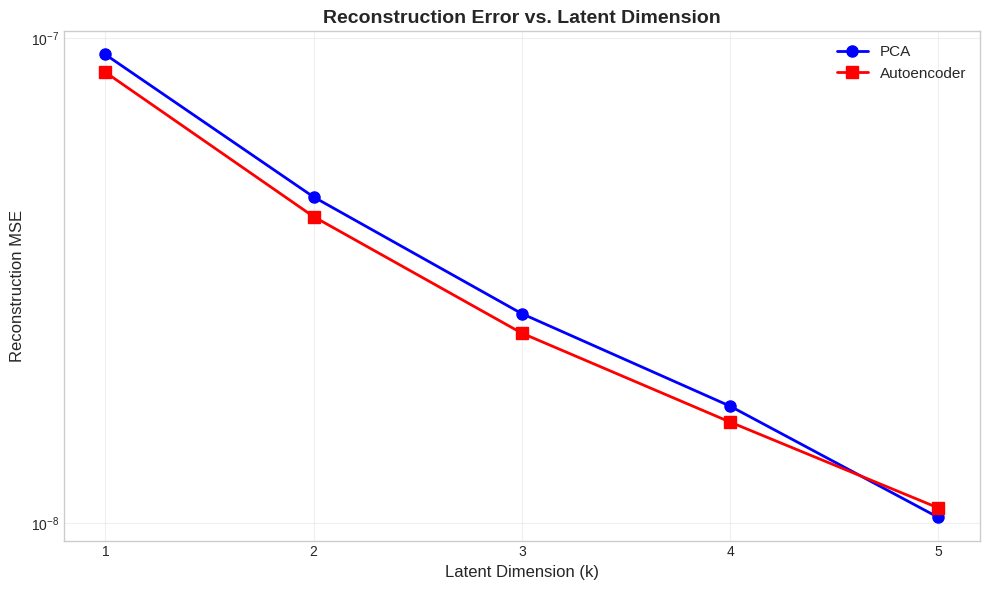

In [19]:
# Plot reconstruction error vs latent dimension
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(latent_dims_to_test, pca_errors, 'b-o', linewidth=2, markersize=8, label='PCA')
ax.plot(latent_dims_to_test, ae_errors, 'r-s', linewidth=2, markersize=8, label='Autoencoder')

ax.set_xlabel('Latent Dimension (k)', fontsize=12)
ax.set_ylabel('Reconstruction MSE', fontsize=12)
ax.set_title('Reconstruction Error vs. Latent Dimension', fontsize=14, fontweight='bold')
ax.set_xticks(latent_dims_to_test)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_yscale('log')

plt.tight_layout()
plt.show()

## 9. Summary and Conclusions

In [20]:
print("="*70)
print("SUMMARY: Autoencoder vs PCA for Yield Curve Dimensionality Reduction")
print("="*70)
print()
print("Key Findings:")
print("-" * 70)
print()
print("1. RECONSTRUCTION QUALITY")
print(f"   - PCA (3 components):  MSE = {comparison.pca_reconstruction_error:.2e}")
print(f"   - Autoencoder (3 dim): MSE = {comparison.autoencoder_reconstruction_error:.2e}")
print()
print("2. INTERPRETABILITY")
print("   - PCA components have clear economic interpretations:")
for interp in pca_result.interpretations:
    print(f"     {interp}")
print("   - Autoencoder latent dimensions lack direct interpretation")
print()
print("3. COMPUTATIONAL CONSIDERATIONS")
print("   - PCA: Fast, deterministic, no hyperparameters")
print("   - Autoencoder: Requires training, hyperparameter tuning")
print()
print("4. WHEN TO USE EACH")
print("   - PCA: When interpretability is crucial, for linear relationships")
print("   - Autoencoder: When capturing nonlinear patterns is important")
print("   - For yield curve data: PCA typically sufficient (linear dynamics)")
print()
print("="*70)

SUMMARY: Autoencoder vs PCA for Yield Curve Dimensionality Reduction

Key Findings:
----------------------------------------------------------------------

1. RECONSTRUCTION QUALITY
   - PCA (3 components):  MSE = 2.70e-08
   - Autoencoder (3 dim): MSE = 2.10e-08

2. INTERPRETABILITY
   - PCA components have clear economic interpretations:
     PC1: Level (parallel shift) - uniform impact across maturities
     PC2: Slope (tilt) - steepening of yield curve
     PC3: Curvature (inverse butterfly) - belly vs wings movement
   - Autoencoder latent dimensions lack direct interpretation

3. COMPUTATIONAL CONSIDERATIONS
   - PCA: Fast, deterministic, no hyperparameters
   - Autoencoder: Requires training, hyperparameter tuning

4. WHEN TO USE EACH
   - PCA: When interpretability is crucial, for linear relationships
   - Autoencoder: When capturing nonlinear patterns is important
   - For yield curve data: PCA typically sufficient (linear dynamics)



---

## Next Steps

- Try with more maturities (higher dimensional data)
- Experiment with deeper autoencoder architectures
- Consider Variational Autoencoders (VAE) for probabilistic representations
- Compare on data with known nonlinear relationships